# Slow Momentum with Fast Reversion - Completed WRDS port

Enze Hu and Jinrui Hu | IEOR 4576

This notebook records the completed 50-instrument PyTorch / SciPy-Numba experiment. The original feature functions are preserved; the LSTM and GP fitting backends are ports rather than execution of the authors' TensorFlow/GPflow modules.

The 36 searches and 1,800 candidate fits are complete. Main exhibits average five test windows from 1995 through 2019; a separately refitted 2020 test is reported separately. This is not an exact Pinnacle numerical replication.

**Run All displays the committed result tables and figures without WRDS access or retraining.** Set `RUN_REPRODUCTION=True` only to launch a new experiment with an authorized data account and suitable compute.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/momentum_lab').is_dir())
sys.path.insert(0, str(ROOT/'src'))
from momentum_lab.paths import initialize_notebook_environment
initialize_notebook_environment()
pd.options.display.max_rows = 60
pd.options.display.max_columns = 15
pd.options.display.float_format = '{:.4f}'.format
T = ROOT/'report/tables/replication'
F = ROOT/'report/figures/replication'
E = ROOT/'report/tables/extension'
print('Project root found.')
print('Completed result display; training disabled by default.')

Project root found.
Completed result display; training disabled by default.


## Completed result display

The default loads the execution manifest and aggregate artifacts under report/. It does not start training. Licensed contract histories, weights and local credentials are not distributed. The existing pipeline can run a new experiment when RUN_REPRODUCTION=True.


In [2]:
CONFIG = 'configs/config.yaml'
MODEL_WORKERS = 3
RUN_REPRODUCTION = False
FRESH_MODELS = False

if RUN_REPRODUCTION:
    from momentum_lab.notebook_runner import run_prepared
    manifest = run_prepared(CONFIG, model_workers=MODEL_WORKERS, fresh_models=FRESH_MODELS)
else:
    manifest = json.loads((ROOT/'report/execution_manifest.json').read_text())
    assert not manifest['missing_experiments'], 'Experiments are incomplete: set RUN_REPRODUCTION=True.'
print('Completed searches:', manifest['completed_experiments'], '/', manifest['expected_experiments'])
print('Candidate fits:', manifest['completed_trials'])
print('Daily CPD rows:', manifest['cpd_daily_rows'])
if RUN_REPRODUCTION:
    T = ROOT/'results/replication/tables'
    F = ROOT/'results/replication/figures'
    E = ROOT/'results/extension/tables'


Completed searches: 36 / 36
Candidate fits: 1800
Daily CPD rows: {'10': 346218, '21': 346218, '63': 346218, '126': 346218, '252': 346218}


## Original methodology and implemented conventions

The reference study is Wood, Roberts and Zohren (2022), *Slow Momentum with Fast Reversion* ([paper](https://arxiv.org/abs/2105.13727)).

For each instrument, positions are selected at close t and evaluated against t-to-t+1 returns. The raw futures panel rolls five business days before the earliest vendor first-notice/last-trade date, selects the nearest eligible maturity with an observed positive settlement, and computes each day's price change within the previously selected contract. Missing historical volume/OI is not treated as a market inception date. For GI, ZW and ZZ, missing composite expiry metadata is supplemented from the vendor's pit-contract calendar for the identical underlying and delivery month. No expiration is inferred from the last observed price. Missing settlements are valued causally at the last observed mark and explicitly counted; these marks are not assumed to be executable fills. An index compounded from these real returns is the input to the authors' preserved feature code.

The features are 1/21/63/126/252-session volatility-normalized returns and MACD pairs (8,24), (16,48), (32,96). The classical MACD baseline maps the mean of the three normalized trend estimates through the author's separate `scale_signal` function, phi(y)=y exp(−y²/4)/0.89, as in equation (7) of the [foundational DMN reference](https://arxiv.org/html/1904.04912). The neural MACD inputs remain untransformed. The author implementation winsorizes the price index at five EWM standard deviations with half-life 252; daily volatility uses a 60-session EWM span. The original-style evaluation uses that implementation's winsorized return labels. The extension evaluates the positions on raw, un-winsorized same-contract returns as a separate tradability diagnostic.

For each trailing l+1 observation window, GP-CPD fits a stationary Matérn 3/2 covariance and a sigmoid-weighted pair of Matérn kernels by L-BFGS-B (maximum 200 iterations). Windows are reinitialized independently, with all stationary parameters set to one; the fitted stationary kernel initializes the changepoint model. Severity is sigmoid(NLML_M − NLML_CP). Relative location follows the author's code, (t−c)/l, which is the complement of the formula printed in equation (10). The Numba Kalman likelihood is algebraically equivalent to the dense GP covariance. Numerical stabilization adds 1e-8 diagonal jitter and bounded log parameters.

The stateless LSTM has 63 time steps, tanh position outputs, input and output dropout, and the pooled negative Sharpe objective on asset-time observations. Training uses non-overlapping sequences, shuffled sequence order, Adam, parameter-wise gradient norm clipping, a maximum output weight norm of three, up to 300 epochs, and 25-epoch validation patience. The PyTorch port freezes its redundant recurrent bias to match Keras' single bias. Backend initialization and optimizer arithmetic need not be bitwise identical to TensorFlow.

Training expands from 1990, with per-instrument chronological 90/10 train/validation splits. Labels crossing a split boundary are purged. An instrument needs at least one 63-step validation sequence and must satisfy Appendix A's first-test eligibility. Test windows are 1995–1999, 2000–2004, 2005–2009, 2010–2014, and 2015–2019; 2020 is reported as a separate frozen one-year test after a pre-2020 refit. This resolves the manuscript's ambiguous '1995–2020' endpoint explicitly; the 2020 window is excluded from the five-window exhibit averages.

All five CPD horizons (10,21,63,126,252) and the no-CPD LSTM are fitted. The main configuration requests 50 distinct random draws from the full published grid per model/window, using automatic CUDA/Metal/CPU selection and pre-test pooled validation Sharpe for selection. The fresh notebook run trains every candidate from random initialization; older model checkpoints are archived and are not used. The paper specifies 50 random-search iterations; the supporting later author repository defaults to diversified validation Sharpe. The inventory and manifest state the executed search count; a configuration file is not evidence that its experiments have run. One complete search repetition is conducted, with base seed 67 and per-candidate seeds 67+trial. Repeated-seed experiments are not represented as executed. Optimized CPD means selecting the lowest validation loss among the five completed CPD models, independently for each test window.

Exhibits 3 and 4 average each metric across the five main test windows. Annual return is compounded CAGR; Sharpe uses arithmetic mean excess P&L and sample volatility. The portfolio uses equal 1/N weights across the fold's eligible instruments, with no-return dates contributing cash. Exhibit 4 follows the later author aggregation code: use one factor, 15% divided by the mean annualized volatility of the five main windows, on the whole daily return series, then recompute each window's metrics. This targets 15% mean window volatility, not 15% in every window. The rounded printed paper is also consistent with linear scaling of averaged dimensional metrics; that display diagnostic is saved separately, because linear scaling of CAGR or drawdown is not identical to recomputation on compounded returns. These ex-post multipliers are not investable risk forecasts. No Sharpe is assumed to improve.

The data substitute is WRDS LSEG/Datastream individual-contract history, not the proprietary Pinnacle CLC panel. Session conventions, roll construction, starting dates and source revisions differ. Appendix A's NR and ZR series remain distinct; discontinued NR is not backfilled. The Euro series has no fabricated pre-euro/Deutsche-Mark extension. Several other markets start later than 1990; these differences and causal stale settlement marks are explicit in the coverage table. Raw futures P&L is expressed relative to each contract's local-currency price; a USD conversion overlay and integer-lot sizing are outside this reproduction. No unavailable Pinnacle values are imputed.


## Data coverage

The full Appendix A mapping is in `configs/universe.csv`. Raw downloads and manifests are local and excluded from version control. A later first date below describes the selected WRDS contract series, not proof that no earlier data exists in any WRDS product.

In [3]:
coverage = pd.read_csv(T/'data_coverage.csv')
display(coverage[['ticker','feature_days','first','last','rolls','stale_mark_days','calendar_reference_fills','equivalence']])

,ticker,feature_days,first,last,rolls,stale_mark_days,calendar_reference_fills,equivalence
0,CC,7521,1990-01-03,2020-12-31,156,1,0,ICE US cocoa
1,DA,5922,1996-01-15,2020-12-31,295,5,0,CME Class III composite
2,GI,6907,1992-07-30,2020-12-31,316,5,152,S&P GSCI composite
3,JO,7525,1990-01-03,2020-12-31,188,1,0,ICE US FCOJ A
4,KC,7519,1990-01-03,2020-12-31,156,1,0,ICE US Coffee C
5,KW,7556,1990-01-03,2020-12-31,156,0,0,KCBT composite
6,LB,7566,1990-01-03,2020-12-31,187,0,0,CME random length
7,NR,6178,1990-01-03,2015-07-10,155,0,0,Pit series ends before 2020; no fabricated con...
8,SB,7519,1990-01-03,2020-12-31,129,0,0,ICE US sugar 11
9,ZA,7539,1990-01-03,2020-12-31,249,6,0,NYMEX combined trading session


## Completed expanding-window experiments

Hyperparameters use pre-test validation observations. The 2020-only test is separate from the five main windows. Recorded fit_seconds may include pauses and scheduling; it is not a benchmark of active compute time.


In [4]:
inventory = pd.read_csv(T/'experiment_inventory.csv')
display(inventory)
display(pd.read_csv(T/'cpd_diagnostics.csv'))
assert not manifest['missing_experiments'], manifest['missing_experiments']

,strategy,fold,instruments,trials,total_epochs,fit_seconds,best_validation_sharpe,best_trial,test_end_exclusive,oos_asset_days
0,LSTM,1995,34,50,4325,127.2190,1.5138,14,2000,42742
1,LSTM,2000,40,50,4734,292.1710,1.2354,47,2005,50099
2,LSTM,2005,48,50,3805,461.7680,0.9735,47,2010,60488
3,LSTM,2010,49,50,2726,432.1570,0.7141,30,2015,61844
4,LSTM,2015,50,50,2397,556.9690,0.4580,25,2020,61952
5,LSTM,2020,50,50,3261,1011.8250,0.4077,15,2021,12372
6,LSTM-CPD-10,1995,34,50,5520,167.8310,1.7371,14,2000,42742
7,LSTM-CPD-10,2000,40,50,5627,503.3750,1.1398,47,2005,50099
8,LSTM-CPD-10,2005,48,50,3268,503.5930,1.0487,14,2010,60488
9,LSTM-CPD-10,2010,49,50,2265,511.3310,0.7138,15,2015,61844


,window,rows,optimizer_converged_fraction,mean_iterations,mean_severity,mean_relative_location
0,10,346218,0.9950,78.2209,0.7721,0.4997
1,21,346218,0.9966,77.8231,0.7938,0.4986
2,63,346218,0.9986,83.5412,0.8435,0.4976
3,126,346218,0.9990,87.4719,0.8844,0.4973
4,252,346218,0.9991,92.9200,0.9191,0.4947


## Exhibit 3 — Raw signal output

Metrics below come from saved out-of-sample positions. Percentage columns use fractional units (0.15 = 15%).

In [5]:
exhibit3 = pd.read_csv(T/'exhibit_3.csv').set_index('strategy')
display(exhibit3)

,annual_return,annual_volatility,sharpe,downside_deviation,sortino,max_drawdown,calmar,positive_fraction,profit_loss_ratio,days,test_windows
strategy,,,,,,,,,,,
LSTM,0.0271,0.0155,1.8147,0.0102,2.9195,0.0189,2.0252,0.5574,1.0830,1291.0000,5
LSTM-CPD-10,0.0286,0.0200,1.6673,0.0134,2.6137,0.0235,1.9270,0.5515,1.0806,1291.0000,5
LSTM-CPD-126,0.0346,0.0211,1.8364,0.0141,2.8855,0.0313,1.9322,0.5568,1.0887,1291.0000,5
LSTM-CPD-21,0.0341,0.0224,1.8496,0.0152,2.9279,0.0280,2.1464,0.5576,1.0916,1291.0000,5
LSTM-CPD-252,0.0371,0.0191,1.9266,0.0123,3.0828,0.0214,2.0131,0.5540,1.1169,1291.0000,5
LSTM-CPD-63,0.0291,0.0224,1.6062,0.0154,2.5109,0.0324,1.5953,0.5560,1.0488,1291.0000,5
LSTM-CPD-Optimised,0.0302,0.0188,1.6023,0.0125,2.4517,0.0249,1.5158,0.5543,1.0540,1291.0000,5
Long Only,0.0295,0.0491,0.6207,0.0346,0.8874,0.1176,0.2802,0.5334,0.9682,1291.0000,5
MACD,0.0260,0.0329,0.8348,0.0228,1.2457,0.0497,0.8081,0.5363,0.9975,1291.0000,5


## Exhibit 4 — Rescaled to 15% volatility

This follows the author aggregation code: a single ex-post factor per strategy targets 15% mean main-window volatility; CAGR and drawdown are recomputed on the scaled daily returns. It is not a tradable volatility forecast.

,annual_return,annual_volatility,sharpe,downside_deviation,sortino,max_drawdown,calmar,positive_fraction,profit_loss_ratio,days,test_windows
strategy,,,,,,,,,,,
LSTM,0.2908,0.1500,1.8147,0.0983,2.9195,0.1699,2.3722,0.5574,1.0830,1291.0000,5
LSTM-CPD-10,0.2305,0.1500,1.6673,0.1006,2.6137,0.1624,2.1664,0.5515,1.0806,1291.0000,5
LSTM-CPD-126,0.2683,0.1500,1.8364,0.1006,2.8855,0.2012,2.2543,0.5568,1.0887,1291.0000,5
LSTM-CPD-21,0.2446,0.1500,1.8496,0.1017,2.9279,0.1730,2.4443,0.5576,1.0916,1291.0000,5
LSTM-CPD-252,0.3284,0.1500,1.9266,0.0964,3.0828,0.1587,2.4073,0.5540,1.1169,1291.0000,5
LSTM-CPD-63,0.2078,0.1500,1.6062,0.1028,2.5109,0.2052,1.8139,0.5560,1.0488,1291.0000,5
LSTM-CPD-Optimised,0.2596,0.1500,1.6023,0.0998,2.4517,0.1843,1.7360,0.5543,1.0540,1291.0000,5
Long Only,0.0850,0.1500,0.6207,0.1057,0.8874,0.3207,0.2889,0.5334,0.9682,1291.0000,5
MACD,0.1170,0.1500,0.8348,0.1041,1.2457,0.2138,0.8524,0.5363,0.9975,1291.0000,5


,strategy,global_ex_post_factor
0,LSTM,9.6473
1,LSTM-CPD-10,7.4965
2,LSTM-CPD-126,7.1184
3,LSTM-CPD-21,6.6928
4,LSTM-CPD-252,7.8619
5,LSTM-CPD-63,6.6977
6,LSTM-CPD-Optimised,7.9888
7,Long Only,3.0565
8,MACD,4.5590
9,TSMOM w=0,3.4472


Separate linear display approximation; these are transformed summary metrics, not recomputed strategy CAGR/MDD:


,annual_return,annual_volatility,sharpe,downside_deviation,sortino,max_drawdown,calmar,positive_fraction,profit_loss_ratio,days,test_windows
strategy,,,,,,,,,,,
LSTM,0.2610,0.1500,1.8147,0.0983,2.9195,0.1822,2.0252,0.5574,1.0830,1291.0000,5
LSTM-CPD-10,0.2145,0.1500,1.6673,0.1006,2.6137,0.1763,1.9270,0.5515,1.0806,1291.0000,5
LSTM-CPD-126,0.2461,0.1500,1.8364,0.1006,2.8855,0.2231,1.9322,0.5568,1.0887,1291.0000,5
LSTM-CPD-21,0.2283,0.1500,1.8496,0.1017,2.9279,0.1876,2.1464,0.5576,1.0916,1291.0000,5
LSTM-CPD-252,0.2920,0.1500,1.9266,0.0964,3.0828,0.1684,2.0131,0.5540,1.1169,1291.0000,5
LSTM-CPD-63,0.1947,0.1500,1.6062,0.1028,2.5109,0.2167,1.5953,0.5560,1.0488,1291.0000,5
LSTM-CPD-Optimised,0.2409,0.1500,1.6023,0.0998,2.4517,0.1987,1.5158,0.5543,1.0540,1291.0000,5
Long Only,0.0903,0.1500,0.6207,0.1057,0.8874,0.3593,0.2802,0.5334,0.9682,1291.0000,5
MACD,0.1184,0.1500,0.8348,0.1041,1.2457,0.2267,0.8081,0.5363,0.9975,1291.0000,5


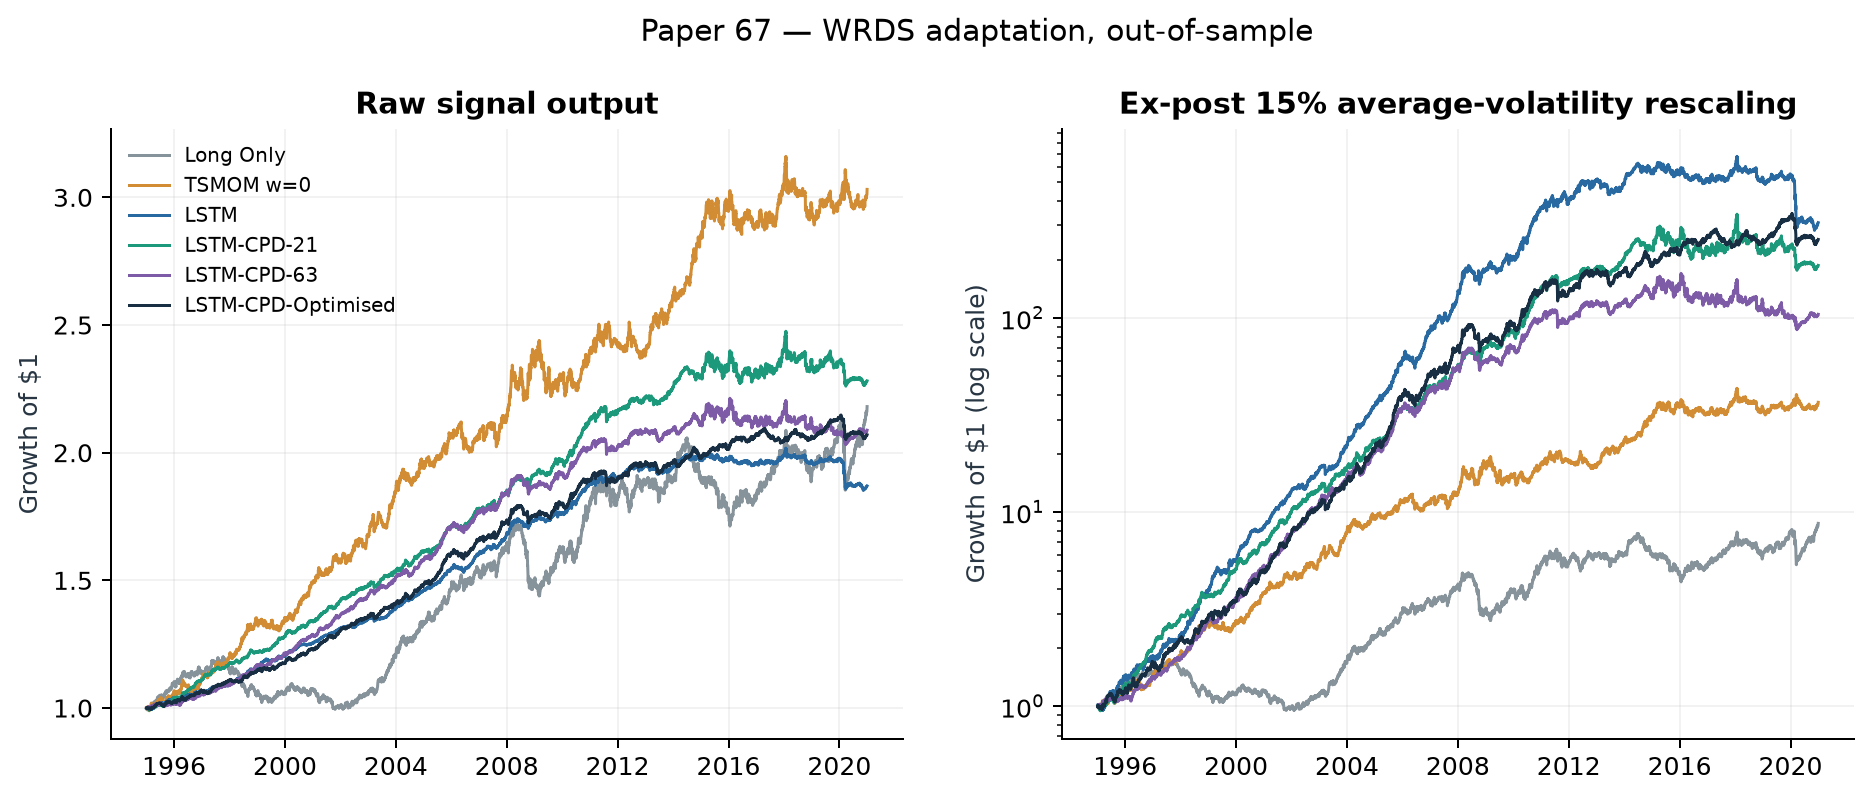

In [6]:
display(pd.read_csv(T/'exhibit_4.csv').set_index('strategy'))
display(pd.read_csv(T/'volatility_rescaling.csv'))
print('Separate linear display approximation; these are transformed summary metrics, not recomputed strategy CAGR/MDD:')
display(pd.read_csv(T/'exhibit_4_linear_display.csv').set_index('strategy'))
display(Image(filename=str(F/'wealth_comparison.png')))

## Comparison with the published study

The 50-candidate search budget matches the paper. Data source, historical coverage, roll construction, random-search realization and numerical backend differ. A failure to recover the published improvement is a substantive empirical outcome.

,strategy,sharpe_published,sharpe_reproduced,sharpe_difference,test_windows,status
0,Long Only,0.4400,0.6207,0.1807,5,executed WRDS adaptation
1,MACD,0.7700,0.8348,0.0648,5,executed WRDS adaptation
2,TSMOM w=0,0.9400,1.0479,0.1079,5,executed WRDS adaptation
3,TSMOM w=0.5,0.8900,0.9682,0.0782,5,executed WRDS adaptation
4,TSMOM w=1,0.4800,0.5311,0.0511,5,executed WRDS adaptation
5,LSTM,1.6200,1.8147,0.1947,5,executed WRDS adaptation
6,LSTM-CPD-10,1.7700,1.6673,-0.1027,5,executed WRDS adaptation
7,LSTM-CPD-21,2.0400,1.8496,-0.1904,5,executed WRDS adaptation
8,LSTM-CPD-63,2.0800,1.6062,-0.4738,5,executed WRDS adaptation
9,LSTM-CPD-126,1.7500,1.8364,0.0864,5,executed WRDS adaptation


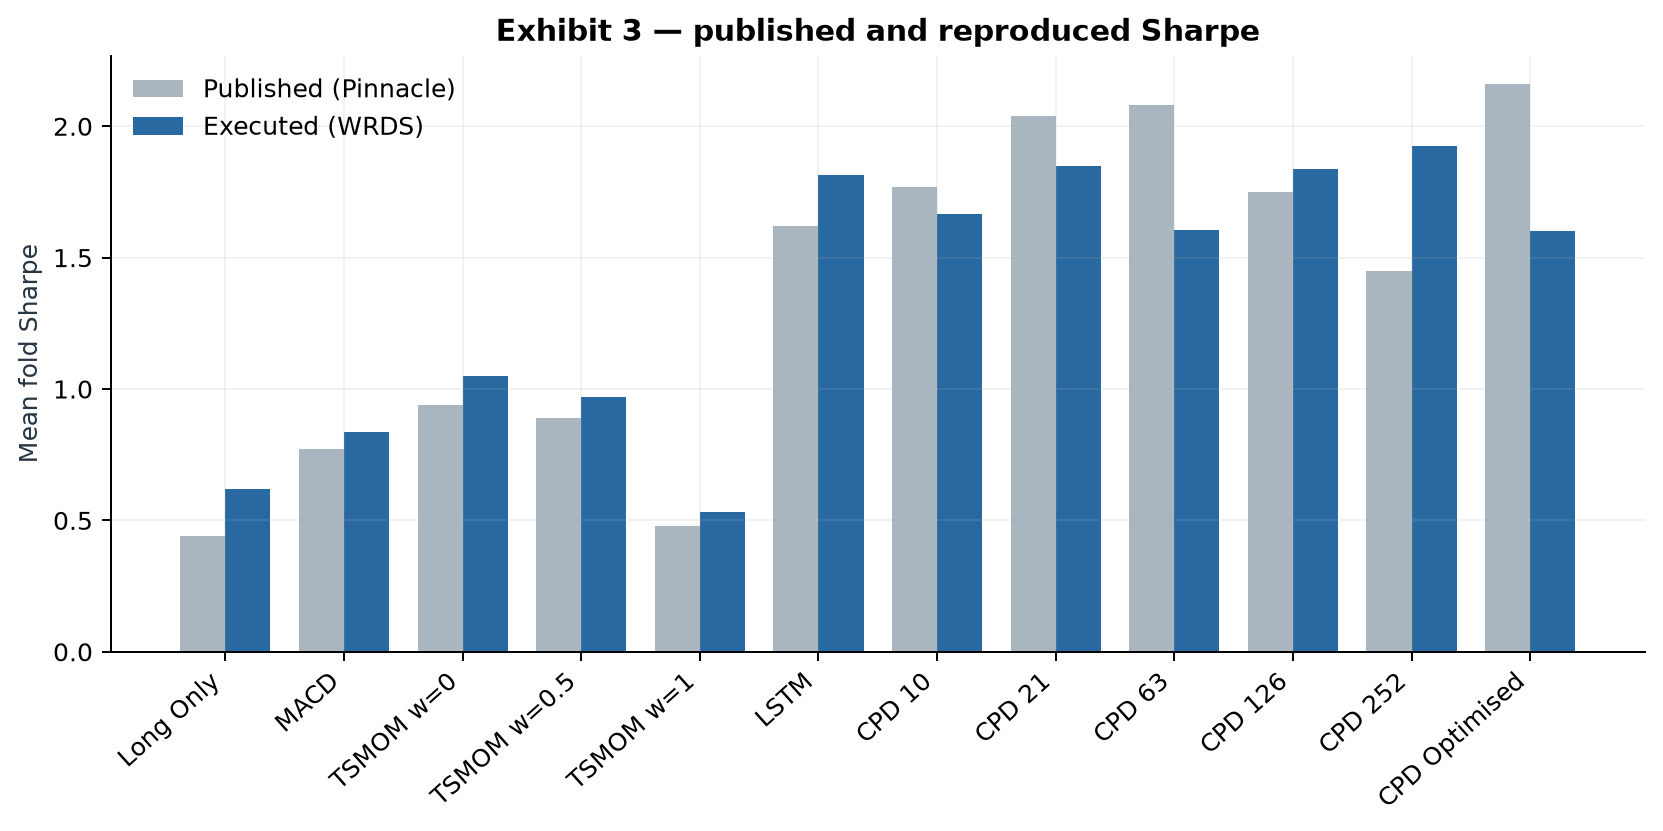

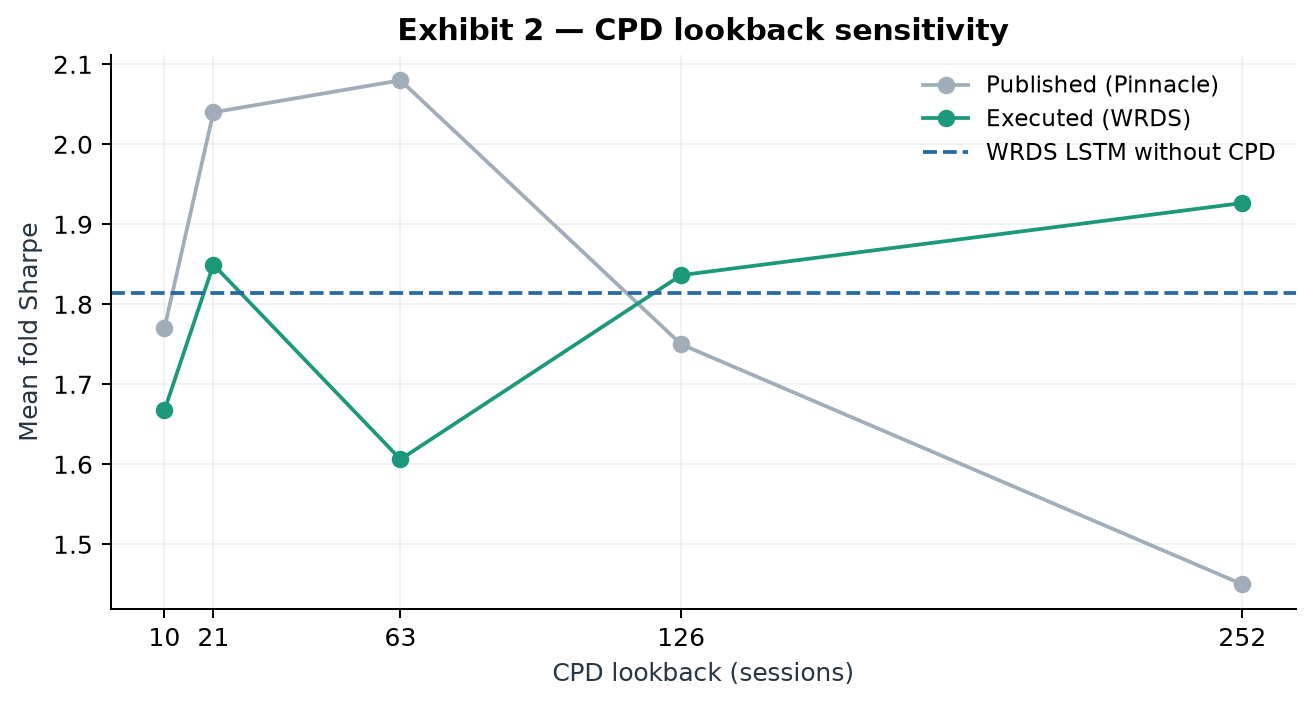

,fold,strategy,validation_loss
0,1995,LSTM-CPD-10,-1.7371
1,2000,LSTM-CPD-21,-1.1468
2,2005,LSTM-CPD-63,-1.1593
3,2010,LSTM-CPD-63,-0.8271
4,2015,LSTM-CPD-252,-0.5246
5,2020,LSTM-CPD-21,-0.4852


In [7]:
comparison = pd.read_csv(T/'published_comparison.csv')
display(comparison[['strategy','sharpe_published','sharpe_reproduced','sharpe_difference','test_windows','status']])
display(Image(filename=str(F/'published_comparison.png')))
display(Image(filename=str(F/'cpd_window_sensitivity.png')))
display(pd.read_csv(T/'selected_cpd_windows.csv'))

## Appendix C — Transaction costs

Costs are in one-way bps of traded notional. Position reversal, volatility resizing, initial entry and final exit are charged. As in Appendix C, the core table uses changes in scaled exposure; the extension adds both futures-roll legs. The vertical line marks the 2.5-bps cost scenario. Costs are hypothetical stress levels, not measured liquidity or impact estimates.

cost_bps,0.0000,0.5000,1.0000,2.0000,2.5000,3.0000,5.0000
strategy,,,,,,,
LSTM,1.8147,1.5119,1.2092,0.6040,0.3016,-0.0005,-1.2057
LSTM-CPD-10,1.6673,1.3362,1.0051,0.3429,0.0120,-0.3188,-1.6394
LSTM-CPD-126,1.8364,1.4917,1.1469,0.4573,0.1127,-0.2317,-1.6068
LSTM-CPD-21,1.8496,1.5588,1.2678,0.6859,0.3950,0.1042,-1.0571
LSTM-CPD-252,1.9266,1.5576,1.1886,0.4506,0.0818,-0.2868,-1.7581
LSTM-CPD-63,1.6062,1.3420,1.0777,0.5492,0.2850,0.0208,-1.0342
LSTM-CPD-Optimised,1.6023,1.2062,0.8101,0.0183,-0.3773,-0.7726,-2.3496
Long Only,0.6207,0.6152,0.6097,0.5987,0.5933,0.5878,0.5659
MACD,0.8348,0.8200,0.8051,0.7754,0.7606,0.7457,0.6863


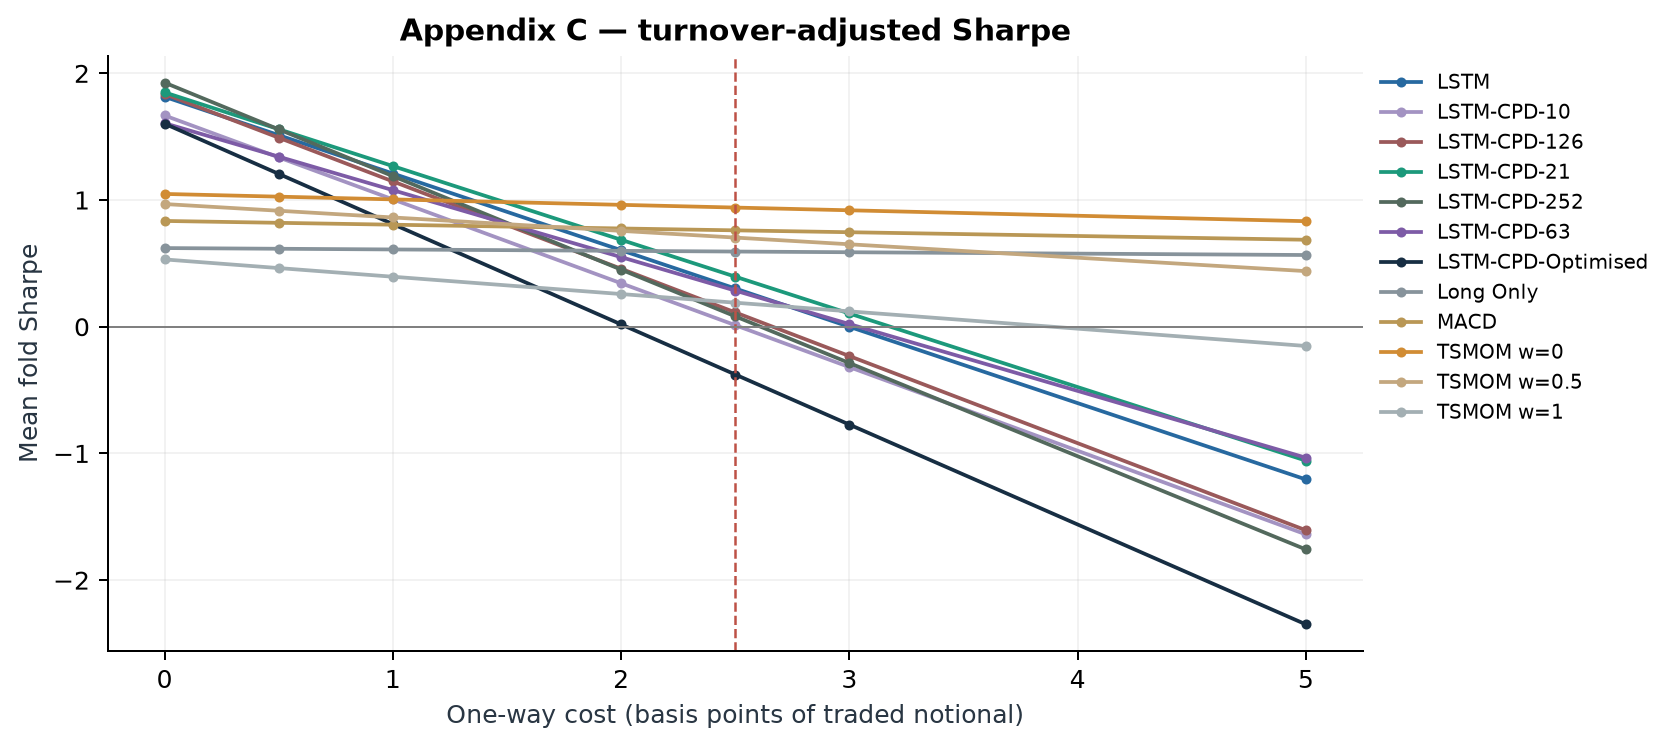

In [8]:
costs = pd.read_csv(T/'transaction_costs.csv')
display(costs.pivot(index='strategy',columns='cost_bps',values='sharpe'))
display(Image(filename=str(F/'transaction_costs.png')))

## Futures rolls and execution sensitivity

Return endpoints always belong to the same contract. On a roll, the near/far settlement gap creates no cash flow. Both old and new traded exposures pay costs. The raw-return and delayed-signal scenarios below use the same already-fitted positions, without retraining on test data. Bid/ask spreads, market impact and integer-lot sizing are not identified by daily settlements.

,strategy,scenario,sharpe,annual_return,max_drawdown,annual_turnover,annual_roll_extra
4,LSTM,2x exposure cap plus rolls,0.3147,0.0034,0.0401,91.3473,2.7564
11,LSTM,one-session signal delay plus rolls,-1.0048,-0.0152,0.0864,96.8120,2.7564
18,LSTM,raw returns plus rolls,0.2575,0.0024,0.0445,96.9137,2.7564
25,LSTM-CPD-10,2x exposure cap plus rolls,0.0429,-0.0013,0.0549,113.2724,4.0151
32,LSTM-CPD-10,one-session signal delay plus rolls,-1.2229,-0.0213,0.1217,124.8467,4.0151
39,LSTM-CPD-10,raw returns plus rolls,-0.0328,-0.0031,0.0610,124.9542,4.0151
46,LSTM-CPD-126,2x exposure cap plus rolls,0.1747,0.0012,0.0627,127.9086,3.9610
53,LSTM-CPD-126,one-session signal delay plus rolls,-1.0884,-0.0223,0.1275,140.9777,3.9610
60,LSTM-CPD-126,raw returns plus rolls,0.0688,-0.0012,0.0701,140.9059,3.9610
67,LSTM-CPD-21,2x exposure cap plus rolls,0.3882,0.0055,0.0433,106.1732,4.8920


,strategy,paper_break_even_bps,raw_roll_break_even_bps,annual_roll_turnover_extra
0,LSTM,2.8356,2.7550,2.7568
1,LSTM-CPD-10,2.3394,2.2642,4.0151
2,LSTM-CPD-126,2.4889,2.4190,3.9605
3,LSTM-CPD-21,3.0564,2.9266,4.8908
4,LSTM-CPD-252,2.6136,2.5564,3.1290
5,LSTM-CPD-63,2.7475,2.6310,4.6320
6,LSTM-CPD-Optimised,2.0367,1.9964,2.9508
7,Long Only,57.4295,15.6579,14.0570
8,MACD,26.9726,13.8562,9.1316
9,TSMOM w=0,23.6222,13.5369,13.7247


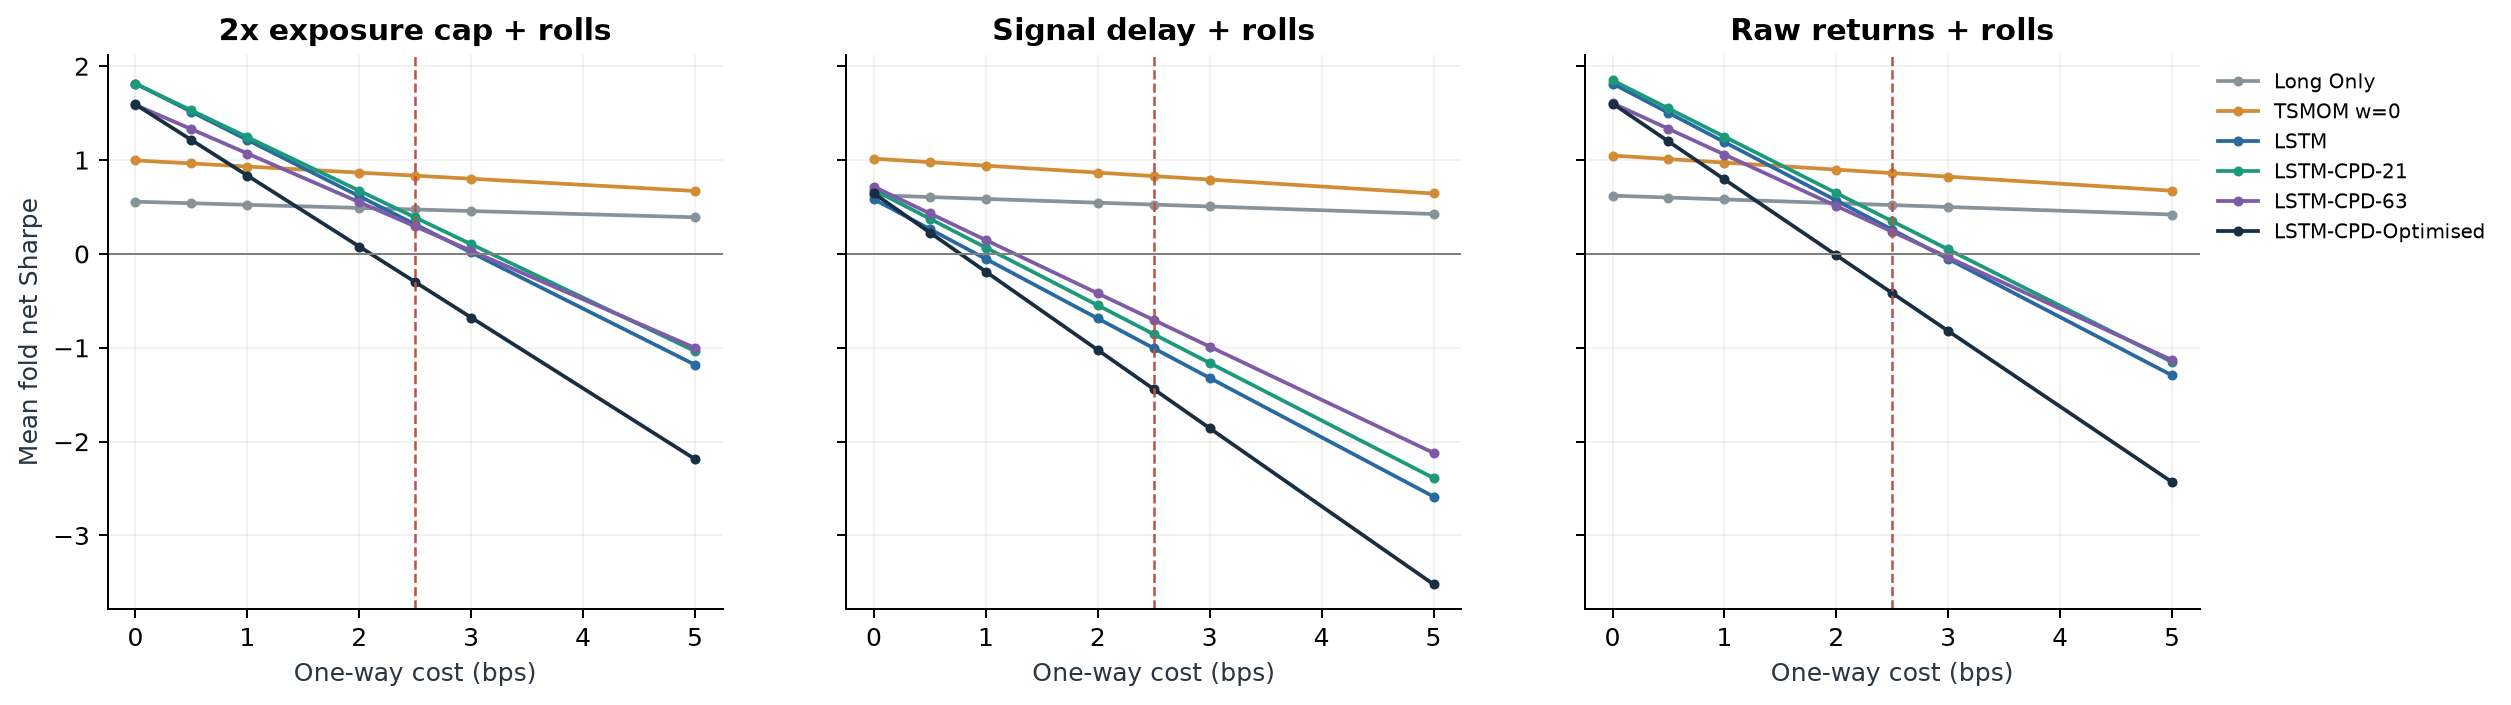

In [9]:
roll = pd.read_csv(E/'roll_costs.csv')
display(roll[roll.cost_bps.eq(2.5)][['strategy','scenario','sharpe','annual_return','max_drawdown','annual_turnover','annual_roll_extra']])
display(pd.read_csv(E/'break_even_costs.csv'))
display(Image(filename=str(ROOT/('results/extension/figures/roll_and_execution_costs.png' if RUN_REPRODUCTION else 'report/figures/extension/roll_and_execution_costs.png'))))

## Risk and regime sensitivity

The 2020 crisis is displayed separately. Position traces use frozen OOS forecasts. A paired 63-session moving-block bootstrap is conditional on the fitted models and does not quantify retraining uncertainty.

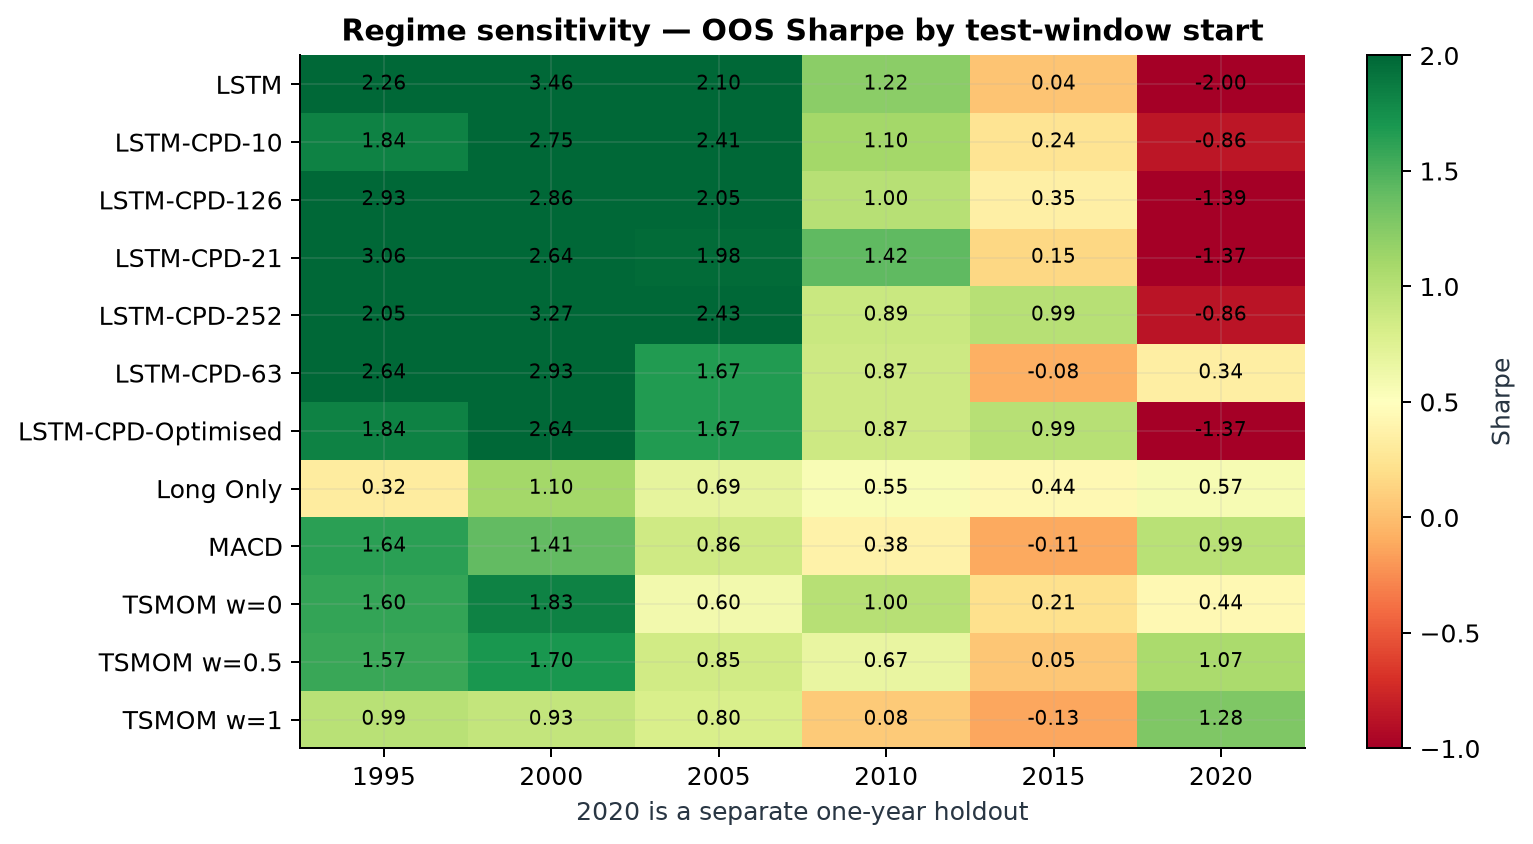

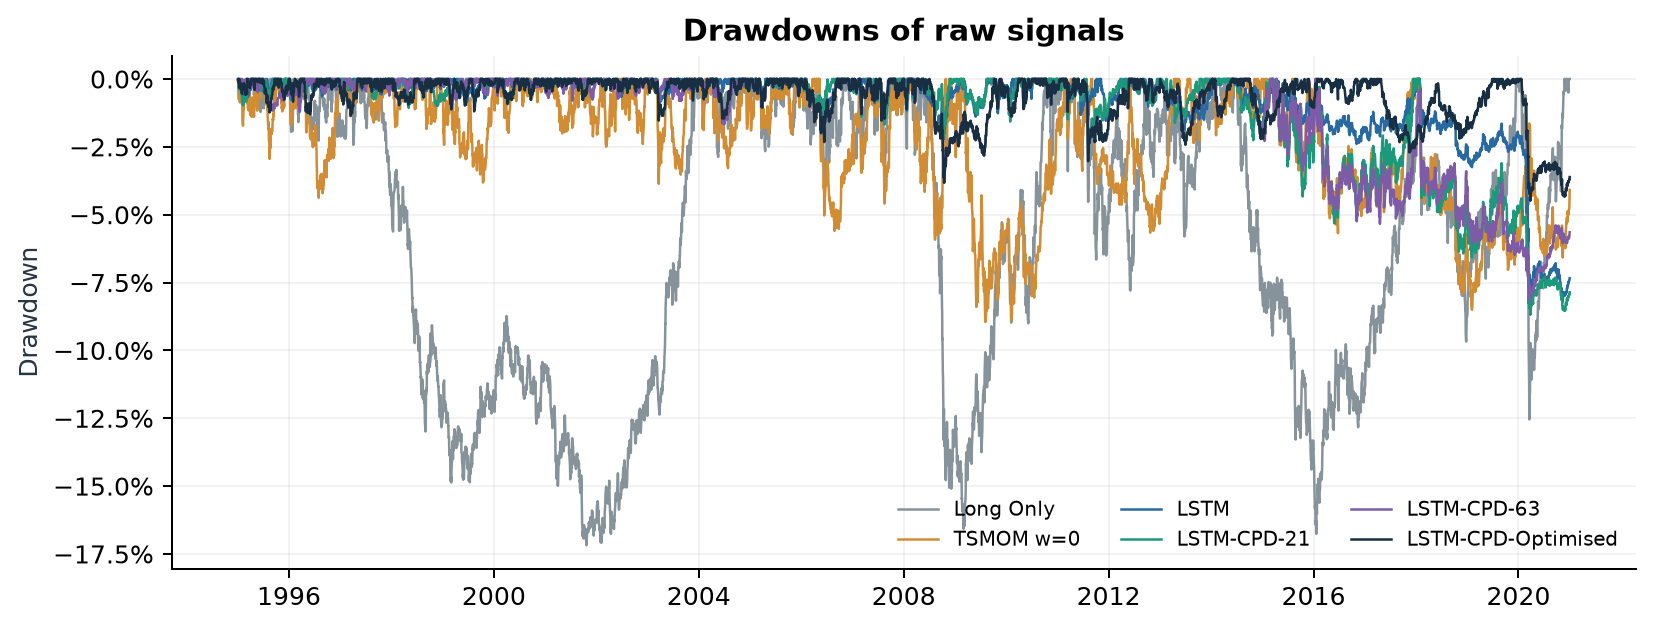

,strategy,difference_vs_lstm,ci_2.5,ci_97.5,bootstrap_samples,block_sessions
0,LSTM-CPD-10,-0.1474,-0.4304,0.1690,500,63
1,LSTM-CPD-126,0.0217,-0.2933,0.3389,500,63
2,LSTM-CPD-21,0.0349,-0.3229,0.3722,500,63
3,LSTM-CPD-252,0.1119,-0.2632,0.4810,500,63
4,LSTM-CPD-63,-0.2085,-0.5948,0.1404,500,63
5,LSTM-CPD-Optimised,-0.2124,-0.6091,0.1638,500,63


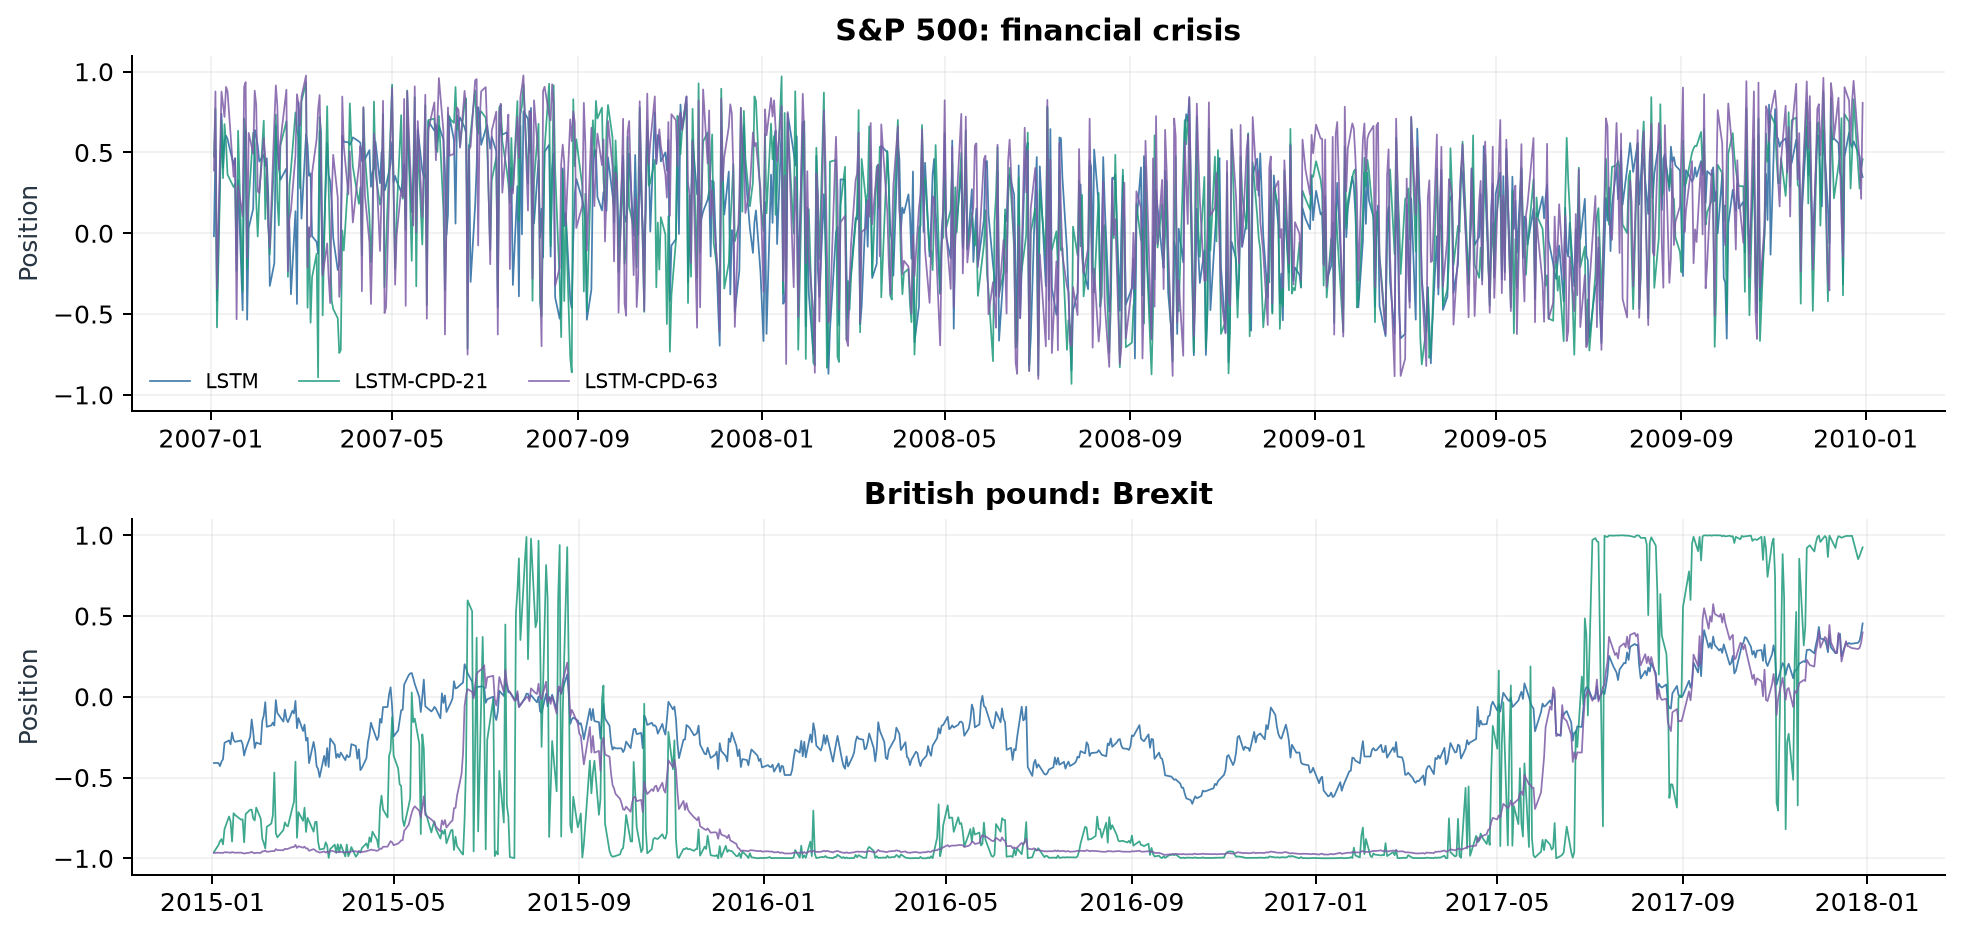

,strategy,year,annual_return,annual_volatility,sharpe,downside_deviation,sortino,max_drawdown,calmar,positive_fraction,profit_loss_ratio,days
25,LSTM,2020,-0.0525,0.0268,-2.0011,0.0244,-2.1968,0.0627,-0.8374,0.4767,0.6741,258
51,LSTM-CPD-10,2020,-0.0190,0.0222,-0.8563,0.0184,-1.0311,0.0392,-0.4859,0.5116,0.7933,258
77,LSTM-CPD-126,2020,-0.0398,0.0289,-1.3896,0.0262,-1.5331,0.0628,-0.6345,0.5233,0.6403,258
103,LSTM-CPD-21,2020,-0.0302,0.0222,-1.3726,0.0198,-1.5366,0.0448,-0.6732,0.5039,0.7304,258
129,LSTM-CPD-252,2020,-0.0257,0.0297,-0.8618,0.0266,-0.9630,0.0519,-0.4957,0.5388,0.7051,258
155,LSTM-CPD-63,2020,0.0071,0.0212,0.3426,0.0173,0.4208,0.0244,0.2896,0.5504,0.8799,258
181,LSTM-CPD-Optimised,2020,-0.0302,0.0222,-1.3726,0.0198,-1.5366,0.0448,-0.6732,0.5039,0.7304,258
207,Long Only,2020,0.0359,0.0660,0.5669,0.0537,0.6972,0.1254,0.2860,0.5891,0.7763,258
233,MACD,2020,0.0407,0.0412,0.9909,0.0260,1.5673,0.0391,1.0418,0.5271,1.0834,258
259,TSMOM w=0,2020,0.0187,0.0448,0.4368,0.0306,0.6386,0.0502,0.3734,0.5426,0.9138,258


In [10]:
display(Image(filename=str(F/'regime_sensitivity.png')))
display(Image(filename=str(F/'drawdowns.png')))
display(pd.read_csv(E/'paired_sharpe_bootstrap.csv'))
display(Image(filename=str(F/'position_diagnostics.png')))
display(pd.read_csv(T/'annual_metrics.csv').query('year == 2020'))

## Conclusions and limitations

In [11]:
if RUN_REPRODUCTION:
    from momentum_lab.reporting import conclusion_text
    display(Markdown(conclusion_text()))
else:
    display(Markdown((ROOT/'report/RESULTS.md').read_text(encoding='utf-8')))

# Completed WRDS replication: results and comparison

This report covers the completed 50-instrument PyTorch / SciPy-Numba experiment based on Wood, Roberts and Zohren, *Slow Momentum with Fast Reversion*. The original return/MACD feature functions are retained. The LSTM and GP fitting backends are ports; this experiment did not execute the original TensorFlow/GPflow pipeline. WRDS individual-contract histories replace the proprietary Pinnacle panel.

The execution manifest records **36 completed searches, 1,800 candidate fits and 126,763 training epochs**. Each search used 50 candidates, a 300-epoch cap and 25-epoch patience. Hyperparameters and CPD horizons were selected from pre-test validation observations. One search repetition was completed.

## Results

Mean five-window gross Sharpe was **1.815 for LSTM** and **1.602 for validation-selected CPD**. Exhibit 3 of the paper reports **1.62** and **2.16**, respectively. The gaps are +0.195 for LSTM and -0.558 for selected CPD. In this run, adding selected CPD reduced Sharpe by 0.212, approximately 11.7%, rather than recovering the paper's roughly one-third improvement. [Published study](https://arxiv.org/html/2105.13727#S4.SS2).

A higher LSTM Sharpe does not mean a higher return: its mean annual return was 2.71%, versus the paper's 3.53%, while volatility was lower at 1.55%, versus 2.52%. Selected CPD returned 3.02% at 1.88% volatility. Its higher return relative to LSTM was accompanied by enough additional risk to reduce Sharpe.

Not every CPD specification underperformed. Fixed 252-session CPD achieved 1.927 Sharpe and fixed 21-session CPD achieved 1.850. The optimized result nevertheless follows validation selection, not the best observed test Sharpe. Its main-fold lookbacks were 10, 21, 63, 63 and 252 sessions. Their weaker subsequent test performance indicates that validation rankings did not reliably carry forward in this realization. Selecting the 252-session result after observing the test outcome would be hindsight selection.

See [the complete comparison](tables/replication/published_comparison.csv), [per-fold results](tables/replication/exhibits_by_fold.csv) and the [executed notebook](Paper67_Original_Study_Replication.ipynb).

## Costs and interpretation

At 2.5 one-way basis points of traded notional, original-style turnover-adjusted Sharpe was **0.302 for LSTM**, **-0.377 for selected CPD** and approximately **0.940 for annual momentum**. Using un-winsorized realized returns and charging both roll legs gave **0.257, -0.418 and 0.860**, respectively. Frequent reversals can therefore consume much of the gross performance in these scenarios.

These are cost sensitivities, not estimates of actual spreads, market impact or capacity. Raw-return and roll-accounting extensions are separate from the paper-style gross comparison. They cannot, by themselves, explain a difference between gross Sharpe figures. [Cost results](tables/replication/transaction_costs.csv); [roll/execution results](tables/extension/roll_costs.csv).

## Sources of differences

**Data construction and coverage.** WRDS histories use an explicit calendar-roll rule and same-contract returns. Sessions, composite series, start dates and discontinued histories differ from Pinnacle. Avoiding cross-contract price gaps does not reconstruct the unavailable vendor series. Return paths, features and the eligible asset pool can all change. [Coverage](tables/replication/data_coverage.csv) and [data decisions](../docs/DATA_DECISIONS.md) record these choices.

**Implementation.** PyTorch training is not bitwise equivalent to Keras. The state-space GP likelihood is algebraically equivalent to dense covariance evaluation, but the port uses numerical gradients, parameter bounds and stabilization that can affect optimization. Likelihood-equivalence tests do not prove identical fitted changepoints, weights or traded positions.

**Random search.** Matching 50 candidates does not recover the authors' unpublished draws, weights or random states. One search repetition cannot distinguish ordinary training variation from systematic implementation or data effects. Bootstrap intervals conditional on fitted positions do not measure retraining uncertainty.

**Dates and aggregation.** This completed version averages 1995-1999, 2000-2004, 2005-2009, 2010-2014 and 2015-2019. A separately refitted 2020 test is excluded from those averages. The paper describes 1995-2020, so the endpoint is not automatically identical. Exhibit 4 uses disclosed ex-post mean-window volatility rescaling, not an investable risk forecast.

These factors change together. The gaps cannot be assigned to the data vendor, backend or training randomness in isolation. The completed run **does not recover the paper's central improvement from validation-selected CPD**. It is evidence about this WRDS implementation, not a refutation of the original experiment.

## Computational scope

The 346,218-row feature panel produces **1,731,090 asset-date/window CPD outputs** across five horizons. Each requires stationary and changepoint GP fitting with iterative likelihood/gradient evaluations and a 200-iteration limit. Dense GP evaluation repeatedly factorizes covariance matrices, with rapidly increasing cost as the lookback grows. The paper also notes greater CPD cost at 126 and 252 sessions. [Study discussion](https://arxiv.org/html/2105.13727#S4.SS3).

The neural stage then performs the 1,800 candidate fits recorded above. GPUs accelerate LSTM training but do not eliminate CPU optimization and model-selection work. Repeated-seed comparisons multiply this workload. Per-fit elapsed fields can include pauses and scheduling, so they are not a clean hardware timing benchmark.

The full configured search budget was completed for this port. A controlled comparison using the original framework, matched data and repeated seeds requires additional computation. Exact numerical recovery also requires original data and execution details; more compute alone cannot supply them. Runtime cost is a practical limitation, not evidence that a discrepancy is acceptable or that its cause is known.

## Evidence and layout

[execution_manifest.json](execution_manifest.json) records configuration, completion counts and input hashes. [experiment_inventory.csv](tables/replication/experiment_inventory.csv) records individual search completions. [result_artifacts_manifest.json](result_artifacts_manifest.json) hashes the committed aggregate artifacts. Published reference values were not inserted into generated returns.

Reusable logic is under src/momentum_lab/, ordered entry points under scripts/, and parameters under configs/. Final notebooks, reports, tables and figures are under report/. Licensed observations, fitted weights, logs, credentials and local environments remain outside Git. See [the repository hierarchy](../resources/repo_hierarchy.txt).


Repeated-seed significance has not been evaluated. Pinnacle's original histories and exact session/roll construction are unavailable in the connected sources. The daily close-t execution assumption is optimistic; the extension reports delayed-signal sensitivity. Fixed bps cannot establish implementable capacity, and MACD usefulness is not independently established by this reproduction. The five-window averaging convention and separate 2020 endpoint are fully specified above.

## Reproduction and provenance

From the prepared repository environment: `make reproduce`. For a new model fit from random initialization: `make fresh`. The final notebook loads reusable module outputs; it is not the source of experiment logic.

Sources: [original paper](https://arxiv.org/abs/2105.13727), [author GP/feature code](https://github.com/kieranjwood/slow-momentum-fast-reversion), [supporting author LSTM code](https://github.com/kieranjwood/trading-momentum-transformer). Preserved MIT licenses and source hashes are recorded in `UPSTREAM.json`. Course requirements and graded feedback were read from the supplied reference folder.

The report manifest records completed runs and feature/configuration hashes. Licensed market data and local credentials are excluded from Git.

In [12]:
print(json.dumps({k:v for k,v in manifest.items() if k not in ['config']}, indent=2))

{
  "paper": "2105.13727v3",
  "generated_utc": "2026-10-31T22:50:46.276619+00:00",
  "completed_experiments": 36,
  "expected_experiments": 36,
  "missing_experiments": [],
  "completed_trials": 1800,
  "completed_epochs": 126763,
  "cpd_daily_rows": {
    "10": 346218,
    "21": 346218,
    "63": 346218,
    "126": 346218,
    "252": 346218
  },
  "hashes": {
    "configs\\config.yaml": "6870a85006fdf7dc432f8f1830fe7ae9b33d053ddbd1616252cc47125dbf7cab",
    "configs\\universe.csv": "ee036776cd551c42e58fb8c4c3a712ed27f4061a3716399e6e8d5d6d145d1689",
    "configs\\extension.yaml": "7bb2af25bbb968b3a84a4ba19e1ac20fa9c865057f22e2b7d0c5517d01a4291c",
    "data\\processed\\features.parquet": "8c12b3a86b8e61810f17a8fe5bf7b2eedb37fab2861ea9a8000823944ca376ce"
  },
  "numerical_replication": "WRDS data adaptation; 50 random-search trials versus the published 50; PyTorch/Numba ports",
  "synthetic_results": false
}
